# Phase 2c — Single out-of-sample run of the static strategy (OOS access #1)

Logged in `EXPERIMENTS.md` **before** computing (2026-10-10 14:06 CEST). This is the only OOS run of the static strategy; no parameter is changed after it.

**Frozen configuration** (pre-registered 2026-10-10 11:56 CEST): log prices; β = 1.0471 estimated on the IS (dates < 2013-01-01) and **not re-estimated**; entry ±2.0, L = 60, exit at zero crossing, direct flip, no stop-loss; `shift(1)`; 5 bp per leg per position change; rf = 0.

**OOS period:** 2013-01-01 to the last available date (2026-10-09). The z-score uses the last 59 IS days as warm-up; the strategy starts flat on the first OOS trading day.

The ADF and Engle–Granger tests on the OOS spread are **descriptive only**.

In [1]:
import logging
from datetime import date

import pandas as pd
import plotly.graph_objects as go
from IPython.display import Image, display

from pairs.backtest import run_strategy
from pairs.config import SPLIT_DATE
from pairs.data import load_pair
from pairs.metrics import performance_summary
from pairs.plotting import DERIVED_COLOR, apply_style, save_figure
from pairs.spread import compute_spread, fit_hedge_ratio, stationarity_tests

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s")
for noisy in ("kaleido", "choreographer"):
    logging.getLogger(noisy).setLevel(logging.WARNING)

# Frozen (EXPERIMENTS.md, 2026-10-10 11:56 and 14:06 CEST). Do not edit.
ENTRY, LOOKBACK, COST_BPS, LAG = 2.0, 60, 5.0, 1
OOS_END = date(2026, 10, 10)  # exclusive: includes the last available date, 2026-10-09

In [2]:
prices = load_pair(end=OOS_END)
assert prices.index.max() == pd.Timestamp("2026-10-09")

# beta is estimated on the IS only (fit_hedge_ratio cuts at SPLIT_DATE first) and frozen.
fit = fit_hedge_ratio(prices, end=SPLIT_DATE)
assert fit.last_date < SPLIT_DATE
assert round(fit.beta, 4) == 1.0471, "frozen beta must match Phase 2"
BETA = fit.beta

INFO pairs.data: Loaded INTC/AMD: 11737 common days, 1980-03-17 -> 2026-10-09 (end=2026-10-10, exclusive)


INFO pairs.spread: Hedge fit (log prices) INTC ~ AMD on 1980-03-17..2012-12-31: alpha=-1.2311 beta=1.0471 R2=0.1499


## 1. Metrics: IS (Phase 2, main configuration) vs OOS

In [3]:
# IS reference: same function and parameters as Phase 2 (identical by construction).
spread_is = compute_spread(prices[prices.index < pd.Timestamp(SPLIT_DATE)], BETA)
is_from = spread_is.index[120 - 1].date()  # Phase 2 common evaluation window
run_is = run_strategy(
    prices,
    BETA,
    entry=ENTRY,
    lookback=LOOKBACK,
    end=SPLIT_DATE,
    trade_from=is_from,
    lag=LAG,
    cost_bps=COST_BPS,
)
sum_is = performance_summary(run_is.daily, run_is.trades)
assert round(sum_is["sharpe_net"], 2) == -0.27 and int(sum_is["n_trades"]) == 115

# OOS access #1: the single out-of-sample run.
run_oos = run_strategy(
    prices,
    BETA,
    entry=ENTRY,
    lookback=LOOKBACK,
    end=OOS_END,
    trade_from=SPLIT_DATE,
    lag=LAG,
    cost_bps=COST_BPS,
)
oos = run_oos.daily
assert oos.index[0] >= pd.Timestamp(SPLIT_DATE) and oos["position"].iloc[0] == 0
assert oos.index[-1] == pd.Timestamp("2026-10-09")
sum_oos = performance_summary(oos, run_oos.trades)

compare = pd.DataFrame({"IS (Phase 2)": sum_is, "OOS": sum_oos})
pct_prefixes = ("ann_return", "ann_vol", "max_dd")
pct_rows = [r for r in compare.index if r.startswith(pct_prefixes)] + ["win_rate_net", "exposure"]
compare.loc[pct_rows] = compare.loc[pct_rows] * 100
compare = compare.rename(index={r: f"{r} %" for r in pct_rows})
periods = pd.DataFrame(
    {
        "IS (Phase 2)": [
            str(run_is.daily.index[0].date()),
            str(run_is.daily.index[-1].date()),
            len(run_is.daily),
        ],
        "OOS": [str(oos.index[0].date()), str(oos.index[-1].date()), len(oos)],
    },
    index=["first day", "last day", "n_days"],
)
display(periods)
compare.round(2)

INFO pairs.backtest: log e=2.0 L=60 lag=1: 115 trades, 1980-09-04..2012-12-31


INFO pairs.backtest: log e=2.0 L=60 lag=1: 51 trades, 2013-01-02..2026-10-09


,IS (Phase 2),OOS
first day,1980-09-04,2013-01-02
last day,2012-12-31,2026-10-09
n_days,8154,3464


,IS (Phase 2),OOS
ann_return_gross %,-7.84,-6.22
ann_vol_gross %,22.22,22.80
sharpe_gross,-0.26,-0.16
max_dd_gross %,-95.93,-81.80
ann_return_net %,-8.16,-6.56
ann_vol_net %,22.22,22.80
sharpe_net,-0.27,-0.18
max_dd_net %,-96.21,-82.44
n_trades,115.00,51.00
win_rate_net %,53.91,60.78


## 2. OOS equity curve, net of costs

INFO pairs.plotting: Saved figure 02f_equity_oos (.html, .png) in C:\Users\cloti\Documents\Projects\challenge_BSQ\reports\figures


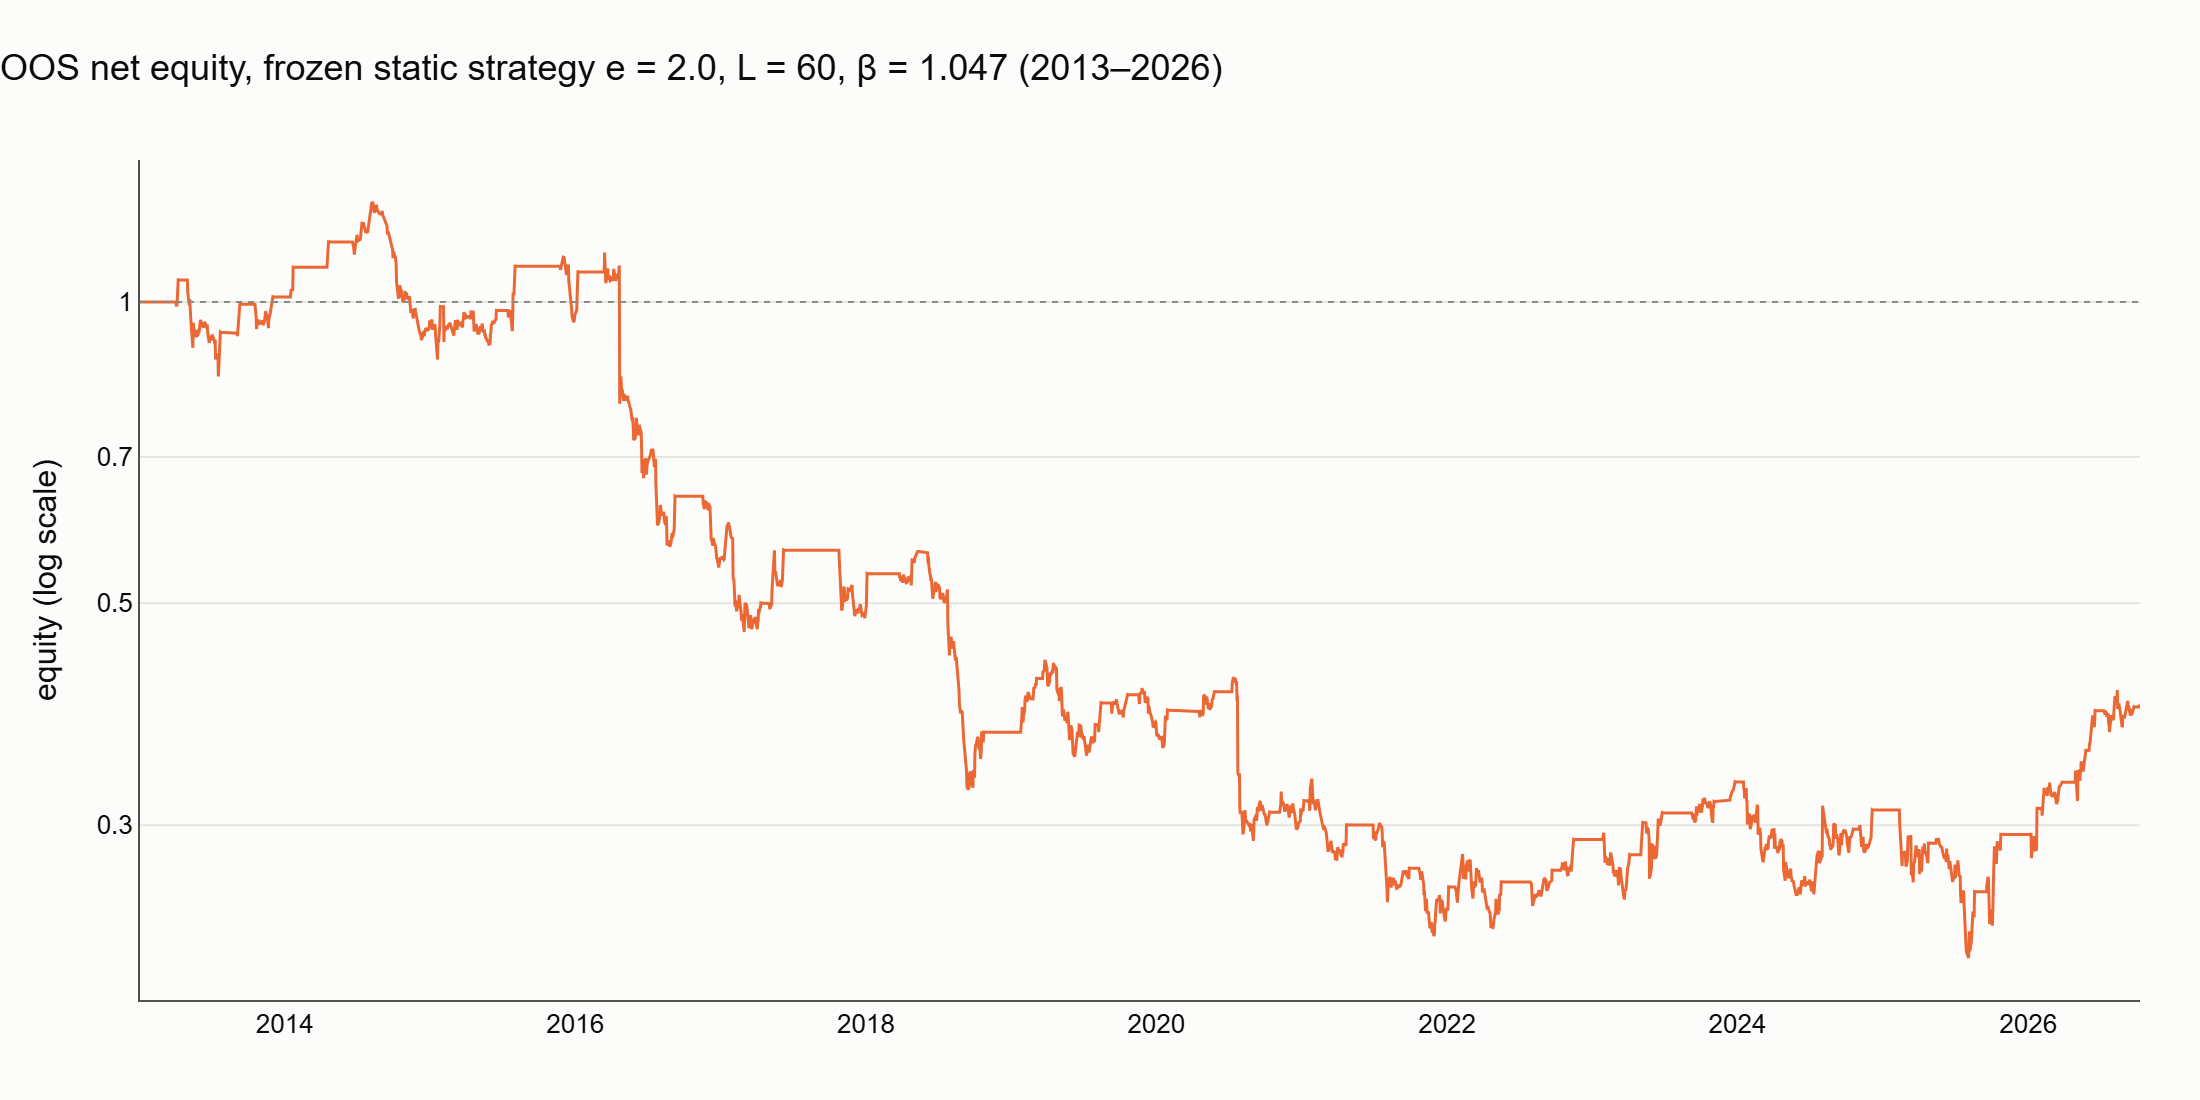

In [4]:
eq_oos = (1 + oos["net_ret"]).cumprod()
fig = go.Figure()
fig.add_trace(
    go.Scatter(
        x=eq_oos.index, y=eq_oos, name="net equity (OOS)", line={"color": "#eb6834", "width": 1.5}
    )
)
fig.add_hline(y=1, line={"color": "#8a8984", "width": 1, "dash": "dot"})
apply_style(fig, "OOS net equity, frozen static strategy e = 2.0, L = 60, β = 1.047 (2013–2026)")
fig.update_layout(showlegend=False)
fig.update_yaxes(
    type="log",
    tickvals=[0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 1, 1.5, 2, 3, 5],
    title_text="equity (log scale)",
)
_, png = save_figure(fig, "02f_equity_oos")
display(Image(filename=png))

## 3. OOS spread with the frozen β = 1.047, and descriptive stationarity tests

The dashed line is the IS mean of the spread (−1.23), the level the static strategy implicitly expects the spread to stay around in the long run; the z-score only uses the rolling 60-day mean.

INFO pairs.plotting: Saved figure 02g_spread_oos (.html, .png) in C:\Users\cloti\Documents\Projects\challenge_BSQ\reports\figures


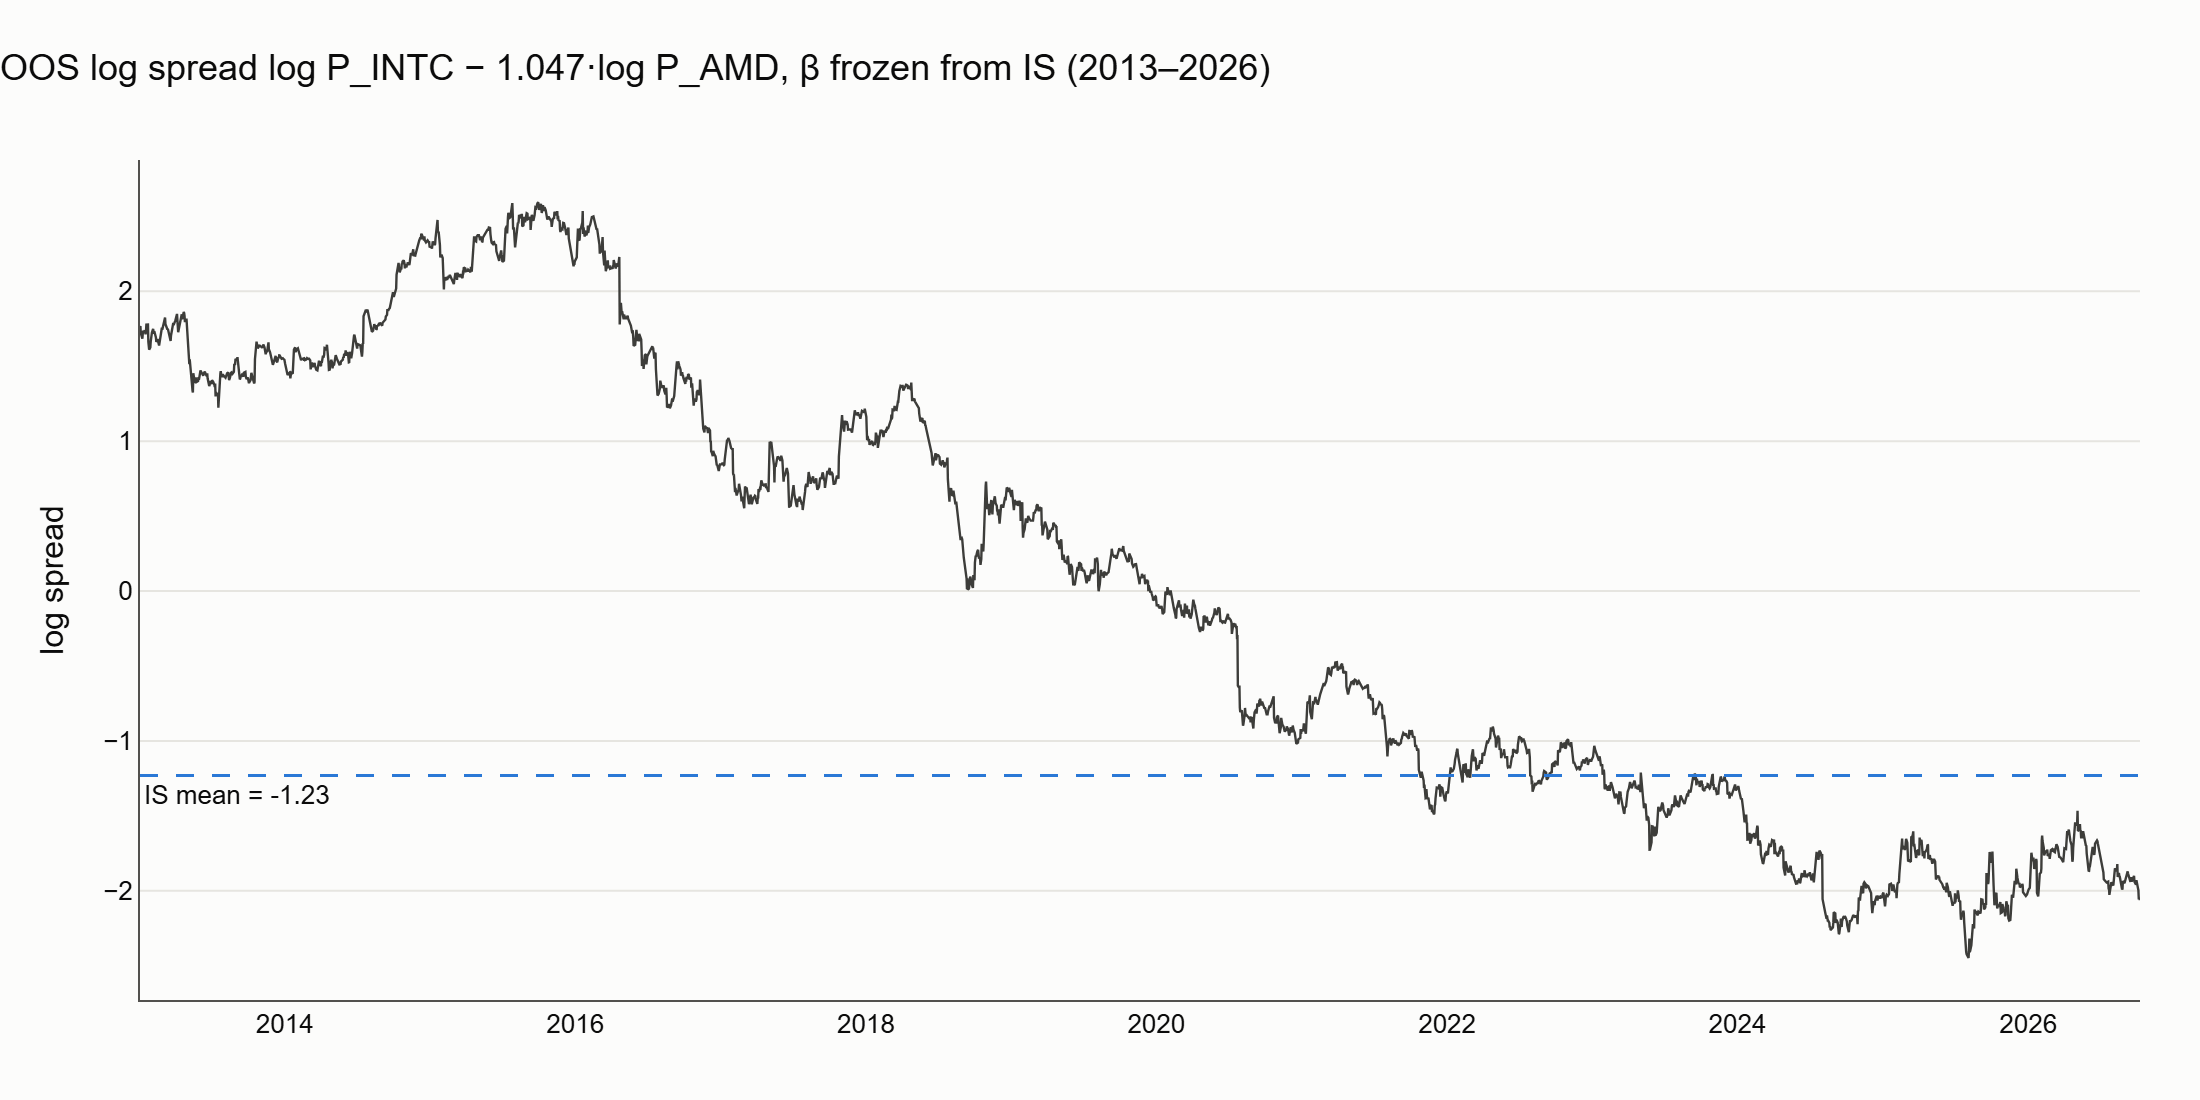

,statistic,p_value
"ADF on OOS spread, frozen β (lags=0)",-0.5130,0.8895
Engle–Granger on OOS log prices,-1.8701,0.5951


Descriptive only. ADF uses the frozen IS β = 1.047; Engle–Granger estimates its own β on the OOS log prices, so it asks whether *any* fixed linear relationship held in 2013–2026.


In [5]:
spread_all = compute_spread(prices, BETA)
spread_oos = spread_all[spread_all.index >= pd.Timestamp(SPLIT_DATE)]
is_mean = float(spread_is.mean())

fig = go.Figure()
fig.add_trace(
    go.Scatter(
        x=spread_oos.index, y=spread_oos, name="spread", line={"color": DERIVED_COLOR, "width": 1.2}
    )
)
fig.add_hline(
    y=is_mean,
    line={"color": "#2a78d6", "width": 1.5, "dash": "dash"},
    annotation_text=f"IS mean = {is_mean:.2f}",
    annotation_position="bottom left",
)
apply_style(fig, f"OOS log spread log P_INTC − {BETA:.3f}·log P_AMD, β frozen from IS (2013–2026)")
fig.update_layout(showlegend=False)
fig.update_yaxes(title_text="log spread")
_, png = save_figure(fig, "02g_spread_oos")
display(Image(filename=png))

prices_oos = prices[prices.index >= pd.Timestamp(SPLIT_DATE)]
st_oos = stationarity_tests(prices_oos, beta=BETA, end=OOS_END)
display(
    pd.DataFrame(
        {
            "statistic": [st_oos.adf_stat, st_oos.eg_stat],
            "p_value": [st_oos.adf_pvalue, st_oos.eg_pvalue],
        },
        index=[
            f"ADF on OOS spread, frozen β (lags={st_oos.adf_lags})",
            "Engle–Granger on OOS log prices",
        ],
    ).round(4)
)
print(
    "Descriptive only. ADF uses the frozen IS β = 1.047; "
    "Engle–Granger estimates its own β on the OOS log prices, "
    "so it asks whether *any* fixed linear relationship held in 2013–2026."
)

## Observations (OOS access #1; nothing changed after this run)

- **The frozen static strategy loses out-of-sample too:** Sharpe −0.16 gross / −0.18 net, −6.2% / −6.6% a year, max drawdown −82% net, 51 trades, net win rate 61%, in the market 60% of the days. The IS result (Sharpe −0.27 net) is confirmed rather than contradicted: the OOS is slightly less bad, but still clearly negative.
- **Same failure mechanism as in-sample.** The OOS spread with the frozen β has no stable level: it rises to a peak in 2015, then trends down for about a decade, falling below the IS mean (−1.23) after 2022. The strategy loses most of its value in 2016–2021, while the spread keeps falling — consistent with Phase 3: the static-β spread is mostly a short AMD position, and AMD strongly outperformed Intel in this period (disclosed prior knowledge, `EXPERIMENTS.md` 11:56). The win rate above 50% with negative returns repeats the IS pattern: small quick wins, larger losses while the spread drifts.
- **Descriptive tests:** ADF on the OOS spread with the frozen β, p = 0.89; Engle–Granger on OOS log prices (own β), p = 0.60. No evidence of a stationary relationship in 2013–2026 either, even letting β be re-estimated on the OOS itself.
- One trade is still open on 2026-10-09 and is closed there for the trade statistics.